# Task 4 Autoencoders

I use a simple and fully connected autoencoder, not denoising or VAE.

each image 28x28 is flattened into a vector of 784 values. The output of the autoencoder has the same size, because the goal is to reconstruct the original image.
The loss function is MSE as we see in the lectures, I don t know any others but it s nice choice since we are aiming to recontstruct the pixel as they aare.

batch size is 128. nothing facny just a standard choice

epochs = 20. MNIST is a simple dataset, so 20 epochs I think should be enough to see if the models learn well as I have alredy seen  in the prevoius tasks that  20-30 is enough



In [ ]:
import time, random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from torchvision import datasets, transforms
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader

SEED = 42
EPOCHS = 20
BS = 128 # batch size
TEST_BS = 1000
N_POINTS = 500

base_dir = Path.cwd()
data_dir = base_dir / "data"


random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)



device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device is", device)


Device is cuda


In [ ]:
my_transform = transforms.ToTensor()
#this is coherent with:
# input in [0,1]
# output  decoder with  Sigmoid in [0,1], therefore:
#  MSE between input and output

train_dset = datasets.MNIST(data_dir, train=True, download=True, transform=my_transform)
test_dset = datasets.MNIST(data_dir, train=False, download=True, transform=my_transform)

train_loader = DataLoader(train_dset, batch_size=BS, shuffle=True)
test_loader = DataLoader(test_dset, batch_size=TEST_BS, shuffle=False)

print("Train len:", len(train_dset))
print("Test len:", len(test_dset))


Train len: 60000
Test len: 10000


### first model:  deep and narrow
784 --> 128 --> 32 --> 8 --> 4 --> 2 , then symmetric
The idea is to reduce the information in more steps by step and learn a more progressive way

### second model : wide and shallow
784 --> 2048 --> 2  ,then symmetric
instead of compressing gradually, the model uses a very large hidden representation and then projects directly into the latent space

In [3]:
class Model1(nn.Module):
    def __init__(self):
        super().__init__()
        # deep and narrow
        self.enc1 = nn.Linear(784, 128)
        self.enc2 = nn.Linear(128, 32)
        self.enc3 = nn.Linear(32, 8)
        self.enc4 = nn.Linear(8, 4)
        self.enc5 = nn.Linear(4, 2)

        self.dec1 = nn.Linear(2, 4)
        self.dec2 = nn.Linear(4, 8)
        self.dec3 = nn.Linear(8, 32)
        self.dec4 = nn.Linear(32, 128)
        self.dec5 = nn.Linear(128, 784)

        self.act1 = nn.ReLU()
        self.act2 = nn.Sigmoid()

    def encoder(self, x):
        h = self.act1(self.enc1(x))
        h = self.act1(self.enc2(h))
        h = self.act1(self.enc3(h))
        h = self.act1(self.enc4(h))
        return self.enc5(h)

    def decoder(self, z):
        h = self.act1(self.dec1(z))
        h = self.act1(self.dec2(h))
        h = self.act1(self.dec3(h))
        h = self.act1(self.dec4(h))
        return self.act2(self.dec5(h))

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z)


In [4]:
class Model2(nn.Module):
    def __init__(self):
        super().__init__()
        # wide and shallow
        self.l1 = nn.Linear(784, 2048)
        self.l2 = nn.Linear(2048, 2)

        self.l3 = nn.Linear(2, 2048)
        self.l4 = nn.Linear(2048, 784)

        self.r = nn.ReLU()
        self.sig = nn.Sigmoid()

    def encoder(self, x):
        out = self.r(self.l1(x))
        return self.l2(out)

    def decoder(self, z):
        out = self.r(self.l3(z))
        return self.sig(self.l4(out))

    def forward(self, x):
        return self.decoder(self.encoder(x))


between the hidden layers, the models use ReLU activations.
But , in the last layer of the decoder,  models use sigmoid, because the pixel values are scaled between 0 and 1, so the output should stay in the same range to keep the reconstruction in the same value range as the input. so the input value and output values are meaningful in the MSE loss

In [ ]:

def count_params(model):
    total = 0
    for p in model.parameters():
        if p.requires_grad:
            total = total + p.numel()
    return total

def train(net, dataloader):
    net = net.to(device)
    loss_fn = nn.MSELoss()
    optimizer = optim.Adam(net.parameters(), lr=0.001)

    loss_list = []

    time_list = []

    for ep in range(EPOCHS):
        net.train()
        tot_l = 0

        t0 = time.time()

        for batch_x, _ in dataloader:
            batch_x = batch_x.view(batch_x.size(0), -1).to(device)

            optimizer.zero_grad()
            preds = net(batch_x)
            l = loss_fn(preds, batch_x)
            l.backward()
            optimizer.step()

            tot_l += l.item()

        avg_l = tot_l / len(dataloader)
        loss_list.append(avg_l)

        t1 = time.time()
        dt = t1 - t0
        time_list.append(dt)
        print("epoch", ep+1, "loss:", round(avg_l, 4), "time:", round(dt, 2))


    return  loss_list, time_list

# reconstruction MSE on the test set, computed with the same scale used in training
#compute the global test MSE by summing all squared errors and dividing by
# the total number of elements
def test(net, dataloader):
    net.eval()

    sq_err_sum = 0.0
    n_elements = 0

    with torch.no_grad():
        for batch in dataloader:
            b_x, _ = batch

            batch_size = b_x.size(0)
            b_x = b_x.view(batch_size, -1)
            b_x = b_x.to(device)

            p = net(b_x)

            diff = p - b_x
            squared_diff = diff ** 2
            batch_sq_err = torch.sum(squared_diff).item()

            sq_err_sum = sq_err_sum + batch_sq_err
            n_elements = n_elements + b_x.numel()

    mean_sq_error = sq_err_sum / n_elements
    return mean_sq_error


'''
Extract the latent representations with their  labels produced by the encoder for all samples
in the dataloader 
'''
def get_z_and_labels(net, dataloader):
    net.eval()

    #list used to collect the latent vectors and the corresponding labels
    all_z = []
    all_y = []

    with torch.no_grad():
        for batch in dataloader:
            # Each batch contains the input data and the corresponding labels.
            b_x, b_y = batch

            
        
            batch_size = b_x.size(0)#flatten each input sample into a vector
            b_x = b_x.view(batch_size, -1)

            b_x = b_x.to(device)

            #pass the input through the encoder only.
            # z is the latent representation learned by the autoencoder
            z = net.encoder(b_x)
            z_numpy = z.cpu().numpy()
            y_numpy = b_y.numpy()

            #store  current batch latent vectors and labels
            all_z.append(z_numpy)
            all_y.append(y_numpy)

    #concatenate all batches into one single array 
    final_z = np.concatenate(all_z)
    final_y = np.concatenate(all_y)

    return final_z, final_y

def latent_metrics(z_arr, y_arr):
    
    #let s split the latent representation into its 2 coordinate
    x = z_arr[:, 0]
    y = z_arr[:, 1]

    # compute the bounds of the latent space
    min_x = float(min(x))
    max_x = float(max(x))
    min_y = float(min(y))
    max_y = float(max(y))

    classes = np.unique(y_arr)

   
    centers = [] #list of centroid for each class
    spreads = [] #list of the spreafds of each class

    for cl in classes:
        # choose only the latent points related to the current class
        pts = z_arr[y_arr == cl]

        # compute  class centroid
        c = pts.mean(axis=0)
        centers.append(c)

        diff_from_center = pts - c
        dist_from_center = np.linalg.norm(diff_from_center, axis=1)
        sp = float(dist_from_center.mean()) #measure of intra-class dispersion as mean Euclidean distance from the centroid
        spreads.append(sp)

  
    cdist = [] #This list describes interclass separation
    # If the class centroids are far apart, it means the clusters are  well separated.
    for i in range(len(centers)):
        for j in range(i + 1, len(centers)):
            a = centers[i]
            b = centers[j]

            diff = a - b
            dist = np.linalg.norm(diff)
            dist = float(dist)

            cdist.append(dist)

    # mean centroid distance: average class separation
    m_dist = float(np.mean(cdist))
    # mean spread: average intra-class compactess
    m_spread = float(np.mean(spreads))

    #separability score
    sep = m_dist / m_spread

    return {
        "x_range": [min_x, max_x],
        "y_range": [min_y, max_y],
        "avg_spread": m_spread,
        "avg_dist": m_dist,
        "separation": float(sep)
    }

def plot_latent(z_arr, y_arr, title_str):
    plt.figure(figsize=(9, 7))
    plt.scatter(z_arr[:,0], z_arr[:,1], c=y_arr, cmap="tab10", s=25, alpha=0.8)
    plt.colorbar(label="Class")
    plt.title(title_str)
    plt.grid(True, alpha=0.3)
    plt.show()

def plot_losses(l1, l2):
    plt.figure()
    plt.plot(l1, label="Deep Model")
    plt.plot(l2, label="Wide Model")
    plt.legend()
    plt.title("Train loss")
    plt.show()


In [6]:
m1 = Model1()
m2 = Model2()

p1 = count_params(m1)
p2 = count_params(m2)

print("model 1 params:", p1)
print("model 2 params:", p2)


model 1 params: 210618
model 2 params: 3224338


I picked 500 random indices from the test set only for the latent-space plots. I use the same points for both models so the visual comparison is fair. The latent metrics are computed on the full test set, not on this 500-point subset

In [ ]:
idx_500 = np.random.choice(len(test_dset), N_POINTS, replace=False)


## Final training and evaluations

Below are the cells for the final runs. I run both models and calculate some stats


epoch 1 loss: 0.071 time: 7.69
epoch 2 loss: 0.0511 time: 7.71
epoch 3 loss: 0.0479 time: 7.1
epoch 4 loss: 0.0463 time: 7.73
epoch 5 loss: 0.0453 time: 7.68
epoch 6 loss: 0.0444 time: 7.18
epoch 7 loss: 0.0438 time: 7.75
epoch 8 loss: 0.0433 time: 7.36
epoch 9 loss: 0.0427 time: 8.16
epoch 10 loss: 0.0422 time: 7.69
epoch 11 loss: 0.0419 time: 7.0
epoch 12 loss: 0.0415 time: 7.63
epoch 13 loss: 0.0412 time: 7.53
epoch 14 loss: 0.0409 time: 6.98
epoch 15 loss: 0.0407 time: 7.62
epoch 16 loss: 0.0406 time: 6.89
epoch 17 loss: 0.0404 time: 7.66
epoch 18 loss: 0.0403 time: 7.6
epoch 19 loss: 0.04 time: 7.53
epoch 20 loss: 0.0399 time: 7.71


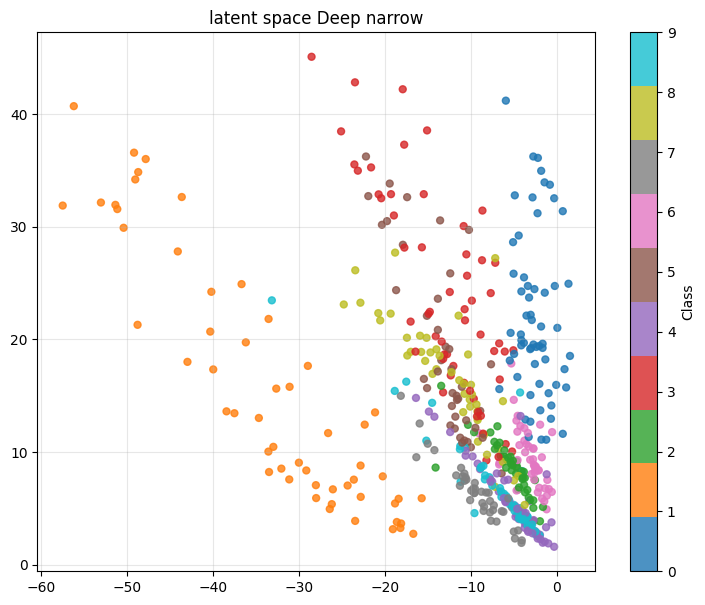

Final Loss Train: 0.03987896142166052
Test MSE: 0.040014275251116074
epoch 1 loss: 0.0521 time: 7.48
epoch 2 loss: 0.0461 time: 6.81
epoch 3 loss: 0.0442 time: 7.37
epoch 4 loss: 0.043 time: 6.8
epoch 5 loss: 0.0422 time: 7.4
epoch 6 loss: 0.0415 time: 7.19
epoch 7 loss: 0.041 time: 7.02
epoch 8 loss: 0.0406 time: 7.4
epoch 9 loss: 0.0403 time: 6.76
epoch 10 loss: 0.0399 time: 7.43
epoch 11 loss: 0.0397 time: 6.91
epoch 12 loss: 0.0395 time: 7.29
epoch 13 loss: 0.0393 time: 7.41
epoch 14 loss: 0.0391 time: 6.85
epoch 15 loss: 0.0389 time: 7.48
epoch 16 loss: 0.0387 time: 6.82
epoch 17 loss: 0.0385 time: 7.46
epoch 18 loss: 0.0384 time: 7.51
epoch 19 loss: 0.0383 time: 6.85
epoch 20 loss: 0.0381 time: 7.51


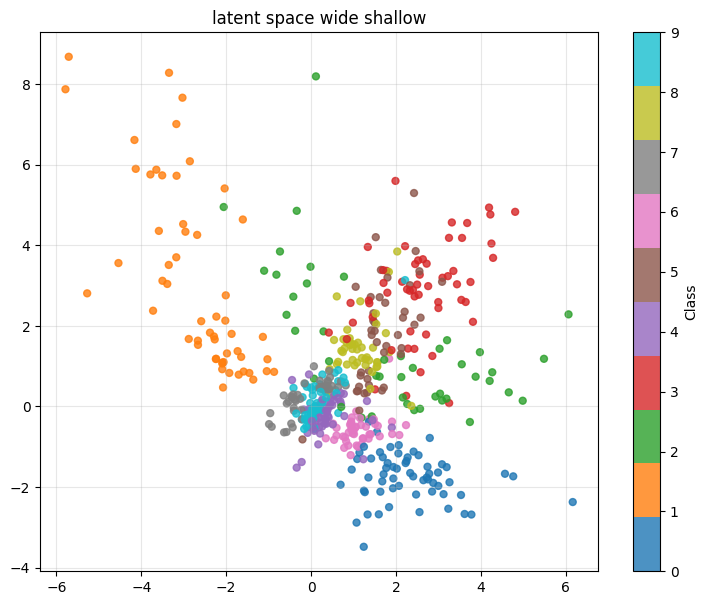

Final Loss Train: 0.03812439052630335
Test MSE: 0.040011154735331636


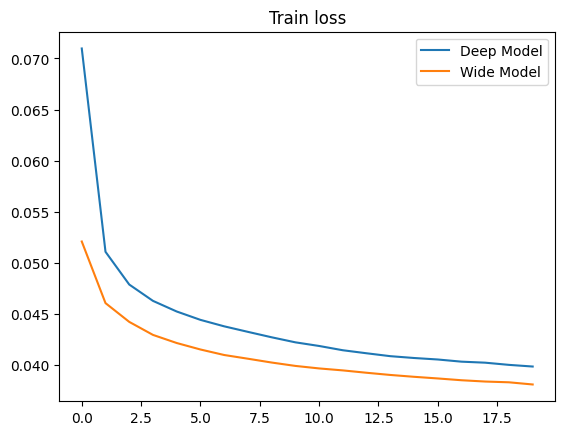

Comparison stats
Params ratio (Model1 / Model2): 0.065321
Spread ratio (Model2 / Model1): 0.175772
Distance ratio (Model2 / Model1): 0.195786
Separation difference (Model2 - Model1): 0.257440
Time ratio (Model2 / Model1): 0.957194

Model 1
Parameters: 210618
Test MSE: 0.040014
X range: [-75.244156, 2.879837]
Y range: [0.788711, 55.202438]
Average spread: 6.125201
Average centroid distance: 13.849124
Separation: 2.261007

Model 2
Parameters: 3224338
Test MSE: 0.040011
X range: [-6.158212, 7.236691]
Y range: [-4.770040, 12.427148]
Average spread: 1.076639
Average centroid distance: 2.711459
Separation: 2.518448


In [ ]:
net1 = Model1()
loss1, t1 = train(net1, train_loader)
test_mse1 = test(net1, test_loader)

z_all1, y_all1 = get_z_and_labels(net1, test_loader)
z_500_1 = z_all1[idx_500]
y_500_1 = y_all1[idx_500]

stats1 = latent_metrics(z_all1, y_all1)

plot_latent(z_500_1, y_500_1, "latent space Deep narrow")

print("Final Loss Train:", loss1[-1])
print("Test MSE:", test_mse1)

net2 = Model2()
loss2 , t2 = train(net2, train_loader)
test_mse2 = test(net2, test_loader)

z_all2, y_all2 = get_z_and_labels(net2, test_loader)
z_500_2 = z_all2[idx_500]
y_500_2 = y_all2[idx_500]

stats2 = latent_metrics(z_all2, y_all2)


plot_latent(z_500_2, y_500_2, "latent space wide shallow")

print("Final Loss Train:", loss2[-1])
print("Test MSE:", test_mse2)

plot_losses(loss1, loss2)



comp = {
    "params_ratio": p1 / p2,
    "spread_ratio": stats2["avg_spread"] / stats1["avg_spread"],
    "dist_ratio": stats2["avg_dist"] / stats1["avg_dist"],
    "sep_diff": stats2["separation"] - stats1["separation"],
    "time_ratio": (sum(t2) / len(t2)) / (sum(t1) / len(t1))
}

print("Comparison stats")
print(f"Params ratio (Model1 / Model2): {comp['params_ratio']:.6f}")
print(f"Spread ratio (Model2 / Model1): {comp['spread_ratio']:.6f}")
print(f"Distance ratio (Model2 / Model1): {comp['dist_ratio']:.6f}")
print(f"Separation difference (Model2 - Model1): {comp['sep_diff']:.6f}")
print(f"Time ratio (Model2 / Model1): {comp['time_ratio']:.6f}")

print("\nModel 1")
print(f"Parameters: {p1}")
print(f"Test MSE: {test_mse1:.6f}")
print(f"X range: [{stats1['x_range'][0]:.6f}, {stats1['x_range'][1]:.6f}]")
print(f"Y range: [{stats1['y_range'][0]:.6f}, {stats1['y_range'][1]:.6f}]")
print(f"Average spread: {stats1['avg_spread']:.6f}")
print(f"Average centroid distance: {stats1['avg_dist']:.6f}")
print(f"Separation: {stats1['separation']:.6f}")

print("\nModel 2")
print(f"Parameters: {p2}")
print(f"Test MSE: {test_mse2:.6f}")
print(f"X range: [{stats2['x_range'][0]:.6f}, {stats2['x_range'][1]:.6f}]")
print(f"Y range: [{stats2['y_range'][0]:.6f}, {stats2['y_range'][1]:.6f}]")
print(f"Average spread: {stats2['avg_spread']:.6f}")
print(f"Average centroid distance: {stats2['avg_dist']:.6f}")
print(f"Separation: {stats2['separation']:.6f}")

The plot is shown on the fixed 500-point subset, while the latent-space statistics are computed on the full test set.

The spread ratio is about 0.176, which means that the average spread of each class in "wide and shallow" is much smaller . This is  a positive sign, because it suggests that the model creates  clusters more concentrated around its centroid. However, this metric alone is not enough to say latent space is better

distance ratio is about 0.196, which means that the average distance between class centroids in "wide and shallow" is also much smaller. So it s not only reducing the spread inside each class, but it is also compressing latent space. This means  has a smaller overall scale. In both models the within-class spread and the between-class distance decrease and increase together

The most informative metric here is the separation difference, which is positive: about +0.257. Since separation is defined as the ratio between average centroid distance and average spread, this  means that the wide autoenc. achieves a better balance between  compactness and  distance. So, from the point of view of latent-space structure,  it s slightly better.(according to the chosen separation metric , I think there will be more sophisticated metrics for this out there)

The time ratio is about 0.957, which means the wide one was also slightly faster . This  is quite  surprising, because the wide one has many more parameters, but it is not impossible because come architecture can  run more efficiently than others on gpu since this hardware accelerates more parallel operations


In [1]:
#This is the real Model2/model 1 param ratio, I invert the ratio by error
1/0.065321

15.309012415609068

# Conclusions 
Both autoencoders reach almost the same reconstruction quality on the test set.  Since all the information must pass through only two latent coordinates, the extra capacity of the larger model gives only a small benefit 

From the point of view of parameter efficiency, the deep and narrow model wins: it reaches almost the same test MSE with about 15 times fewer parameters. (not for the  time of run, but they are almost identical so I consider their difference not significative). So, in this experimetn hugely increasing the width (and model complexity) does not bring  practical benefit 

For the latent space, the wide  model looks slightly better. Its absolute distances between class clusters are small, but its within-class spread is  smaller. Because of this, the distance/spread ratio, which is the separation metric, is higher.  anyway this structural advantage is not enough to produce a clear improvement in test reconstruction

In conclusion,  the wide and shallow model seems to learn a slightly cleaner latent space, but the deep and narrow model is much more efficient and reaches almost the same final result with a much smaller number of parameters